# 01 Cohort

Which patients we curate, which tumor samples they have, and which data types come from the same tumor sample.

- **Cohort:** CBTN patients with miRNA data in our six tumor types. miRNA (HTG EdgeSeq panel) exists only in OpenPedCan v15, so v15 defines the cohort.
- **WGS, RNA-seq and methylation:** files from the newest CBTN release on CAVATICA (`cavatica/pbta-cbttc`, manifests downloaded 2026-10-20 by `workflow/scripts/00_download_cbtn_2026.py`).
- **Same tumor sample:** same CBTN `sample_id` (one piece of tumor). Each data type has its own biospecimen ID, so this table becomes the sample map of the MultiAssayExperiment.

**Outputs** (in `data/procdata/01_cohort/`, not on GitHub):

| File | Content |
|---|---|
| `cohort_patients.csv` | One row per patient: tumor type, subtype, data types, same-sample flags |
| `sample_map.csv` | One row per patient, data type and biospecimen, with the CBTN sample ID and files |
| `cased_sequenced.csv` | Which data types each patient has, in the ICB_Common format (`;`-separated, 0/1) |

This notebook shows counts and plots only, no patient-level rows.

## 1. Setup

In [1]:
suppressPackageStartupMessages({
  library(data.table)
  library(ggplot2)
  library(UpSetR)
  library(scales)
})
options(width = 120, repr.plot.width = 9, repr.plot.height = 5, repr.plot.res = 120)

# Folders come from pixi (PIXI_PROJECT_ROOT); fall back to the repo root when run from workflow/notebooks/
root <- Sys.getenv("PIXI_PROJECT_ROOT", unset = normalizePath(file.path("..", "..")))
RAWDATA      <- file.path(root, "data", "rawdata")
MANIFEST_DIR <- file.path(RAWDATA, "cbtn_2026", "manifests_2026-10-20")
OUT          <- file.path(root, "data", "procdata", "01_cohort")
dir.create(OUT, recursive = TRUE, showWarnings = FALSE)

SIX_TYPES <- c("Low-grade glioma", "Ependymoma", "Medulloblastoma", "Ganglioglioma",
               "High-grade glioma", "Adamantinomatous Craniopharyngioma")
ASSAYS    <- c("WGS", "RNA-Seq", "Methylation", "miRNA-Seq")

# One fixed color per tumor type, used in every notebook (checked for color-blind separation)
TYPE_COLORS <- setNames(c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"), SIX_TYPES)
INK <- c(primary = "#0b0b0b", secondary = "#52514e", muted = "#898781", grid = "#e1e0d9")
theme_bp <- theme_minimal(base_size = 11) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.y = element_blank(),
        panel.grid.major.x = element_line(colour = INK[["grid"]], linewidth = 0.3),
        axis.text = element_text(colour = INK[["secondary"]]), axis.title = element_text(colour = INK[["secondary"]]),
        plot.title = element_text(colour = INK[["primary"]], face = "bold"),
        plot.subtitle = element_text(colour = INK[["secondary"]]),
        strip.text = element_text(colour = INK[["primary"]], face = "bold", hjust = 0),
        legend.position = "top", legend.justification = "left",
        plot.background = element_rect(fill = "#fcfcfb", colour = NA))

## 2. Patients with miRNA in the six tumor types

The tumor type of a patient is the type of their miRNA sample (`cancer_group` in OpenPedCan v15).

In [2]:
hist <- fread(file.path(RAWDATA, "openpedcan_v15", "histologies.tsv"), na.strings = c("", "NA"))
mirna <- hist[experimental_strategy == "miRNA-Seq" & cancer_group %in% SIX_TYPES]
cohort_ids <- unique(mirna$Kids_First_Participant_ID)

cat("miRNA samples:", nrow(mirna), "| patients:", length(cohort_ids), "\n")
two_types <- mirna[, .(n = uniqueN(cancer_group)), by = Kids_First_Participant_ID][n > 1]
cat("Patients with miRNA samples of two tumor types:", nrow(two_types), "\n\n")

mirna[, .(patients = uniqueN(Kids_First_Participant_ID), miRNA_samples = .N), by = .(tumor_type = cancer_group)][
  order(-patients)]

miRNA samples: 225 | patients: 203 


Patients with miRNA samples of two tumor types: 1 



tumor_type,patients,miRNA_samples
<chr>,<int>,<int>
Low-grade glioma,94,100
Ependymoma,30,35
Medulloblastoma,28,31
High-grade glioma,18,23
Ganglioglioma,18,20
Adamantinomatous Craniopharyngioma,16,16


## 3. Samples for each data type

- **miRNA:** OpenPedCan v15 samples.
- **WGS, RNA-seq, methylation:** the files we downloaded from the newest release. WGS counts when the sample has a somatic mutation file (consensus MAF) or a copy-number file. Targeted panels (DGD) are not WGS and are left out.

In [3]:
read_manifest <- function(f) {
  d <- fread(f, sep = "\t", quote = "", colClasses = "character", na.strings = c("", "NA"))
  d[, manifest := basename(f)]
}
man <- rbindlist(lapply(list.files(MANIFEST_DIR, pattern = "\\.tsv$", full.names = TRUE), read_manifest), fill = TRUE)
setnames(man, c("Kids First Participant ID", "Kids First Biospecimen ID"), c("patient", "biospecimen"))

log <- fread(file.path(RAWDATA, "cbtn_2026", "download_log.tsv"), colClasses = "character")
stopifnot(all(log$status %in% c("downloaded", "present")))   # every file arrived with the right size
files <- man[name %in% log$name & sample_type == "Tumor" & patient %in% cohort_ids]

# Data type of each file: from its name, then the experimental strategy of its biospecimen
files[, kind := fcase(grepl("rsem.genes.results", name), "expr",
                      grepl("consensus_somatic", name), "snv",
                      grepl("call.seg|controlfreec|gatk_cnv", name), "cna",
                      grepl("\\.idat", name), "methyl")]
strategy <- unique(man[!is.na(experimental_strategy), .(biospecimen, experimental_strategy)])
files <- merge(files, strategy[, .(strategy = experimental_strategy[1]), by = biospecimen], by = "biospecimen", all.x = TRUE)
files[, assay := fcase(kind == "expr", "RNA-Seq", kind == "methyl", "Methylation",
                       kind %in% c("snv", "cna") & strategy == "WGS", "WGS", default = NA_character_)]
cat("Downloaded tumor files for the cohort:", nrow(files), "\n")
files[, .N, by = .(kind, assay)][order(kind)]

Downloaded tumor files for the cohort: 1844 


kind,assay,N
<chr>,<chr>,<int>
cna,WGS,822
expr,RNA-Seq,263
methyl,Methylation,480
snv,WGS,275
snv,NA,4


In [4]:
# Sample map: one row per patient, data type and biospecimen
newest <- files[!is.na(assay), .(files = paste(sort(name), collapse = ";"),
                                  snv = any(kind == "snv"), cna = any(kind == "cna")),
                by = .(patient, assay, biospecimen, sample_id)]
newest[, source := "CBTN 2026 (CAVATICA)"]
mir <- mirna[, .(patient = Kids_First_Participant_ID, assay = "miRNA-Seq", biospecimen = Kids_First_Biospecimen_ID,
                 sample_id, files = "openpedcan_v15/mirna-expression-counts.rds", snv = FALSE, cna = FALSE,
                 source = "OpenPedCan v15")]
sample_map <- rbind(newest, mir)
sample_map[, assay := factor(assay, levels = ASSAYS)]
setorder(sample_map, patient, assay, sample_id)

# Check against v15: tumor samples of these patients that v15 has but the newest download does not
v15 <- hist[Kids_First_Participant_ID %in% cohort_ids & sample_type == "Tumor" &
            experimental_strategy %in% c("WGS", "RNA-Seq", "Methylation")]
missing <- v15[!Kids_First_Biospecimen_ID %in% newest$biospecimen]
cat("v15 biospecimens (WGS/RNA/methylation) not in the newest download:", nrow(missing), "\n")
if (nrow(missing)) print(missing[, .N, by = experimental_strategy])
cat("\nBiospecimens per data type:\n")
sample_map[, .(patients = uniqueN(patient), biospecimens = .N, tumor_samples = uniqueN(sample_id)), by = assay]

v15 biospecimens (WGS/RNA/methylation) not in the newest download: 1 


   experimental_strategy     N
                  <char> <int>
1:                   WGS     1



Biospecimens per data type:


assay,patients,biospecimens,tumor_samples
<fct>,<int>,<int>,<int>
WGS,195,279,251
RNA-Seq,193,263,242
Methylation,202,240,240
miRNA-Seq,203,225,224


## 4. Same tumor sample

- **Core:** WGS, RNA-seq and methylation from the same tumor sample (same `sample_id`).
- **Core + miRNA:** a core sample that also has miRNA.

The 9 Oct plan counted 190 core + miRNA patients. That count took any WGS file; here WGS needs somatic mutation or copy-number calls, which curation uses. Four patients have WGS in the 9 Oct table but no call files in the newest release, so the count here is lower.

In [5]:
by_sample <- sample_map[, .(assays = list(unique(as.character(assay)))), by = .(patient, sample_id)]
by_sample[, core := vapply(assays, function(a) all(c("WGS", "RNA-Seq", "Methylation") %in% a), logical(1))]
by_sample[, core_mirna := core & vapply(assays, function(a) "miRNA-Seq" %in% a, logical(1))]

pt <- sample_map[, .(has_WGS = any(assay == "WGS"), has_RNA = any(assay == "RNA-Seq"),
                     has_methylation = any(assay == "Methylation"), has_miRNA = any(assay == "miRNA-Seq"),
                     has_snv = any(snv), has_cna = any(cna)), by = patient]
pt <- merge(pt, by_sample[, .(core = any(core), core_mirna = any(core_mirna),
                              core_samples = paste(sample_id[core], collapse = ";")), by = patient], by = "patient")

# Tumor type and subtype of the miRNA sample
tt <- mirna[, .(tumor_type = paste(sort(unique(cancer_group)), collapse = "; "),
                molecular_subtype = paste(sort(unique(na.omit(molecular_subtype))), collapse = "; ")),
            by = .(patient = Kids_First_Participant_ID)]
pt <- merge(tt, pt, by = "patient", all.x = TRUE)
pt[, same_sample_status := fcase(
  core_mirna, "All four from one sample",
  core, "WGS, RNA, methylation from one sample; miRNA from another",
  has_WGS & has_RNA & has_methylation, "All four present, not from one sample",
  default = "Missing at least one data type")]

counts <- pt[, .(patients = .N, WGS = sum(has_WGS), RNA = sum(has_RNA), methylation = sum(has_methylation),
                 core = sum(core), core_plus_miRNA = sum(core_mirna)), by = tumor_type][order(-patients)]
rbind(counts, counts[, c(.(tumor_type = "All six"), lapply(.SD, sum)), .SDcols = -"tumor_type"])

tumor_type,patients,WGS,RNA,methylation,core,core_plus_miRNA
<chr>,<int>,<int>,<int>,<int>,<int>,<int>
Low-grade glioma,93,90,90,93,88,88
Ependymoma,30,28,29,30,26,26
Medulloblastoma,28,27,24,28,24,24
Ganglioglioma,18,18,18,17,17,17
High-grade glioma,17,15,15,17,14,14
Adamantinomatous Craniopharyngioma,16,16,16,16,16,16
High-grade glioma; Low-grade glioma,1,1,1,1,1,1
All six,203,195,193,202,186,186


## 5. Plots

The plots by tumor type leave out the one patient whose miRNA samples are of two tumor types (listed as "High-grade glioma; Low-grade glioma" in the table above).

### Data types per patient (UpSet)

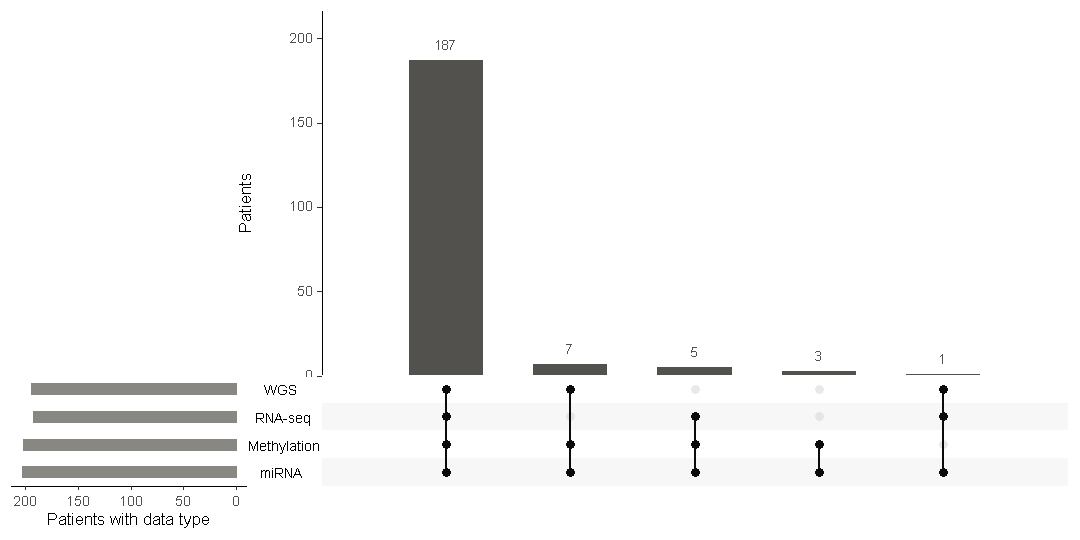

In [6]:
options(repr.plot.width = 9, repr.plot.height = 4.5, warn = -1)  # UpSetR prints ggplot2 deprecation warnings
up <- as.data.frame(pt[, .(WGS = as.integer(has_WGS), `RNA-seq` = as.integer(has_RNA),
                           Methylation = as.integer(has_methylation), miRNA = as.integer(has_miRNA))])
upset(up, sets = c("miRNA", "Methylation", "RNA-seq", "WGS"), keep.order = TRUE, order.by = "freq",
      main.bar.color = INK[["secondary"]], sets.bar.color = INK[["muted"]], matrix.color = INK[["primary"]],
      mainbar.y.label = "Patients", sets.x.label = "Patients with data type", text.scale = 1.2)
options(warn = 0)

### Patients per tumor type and molecular subtype

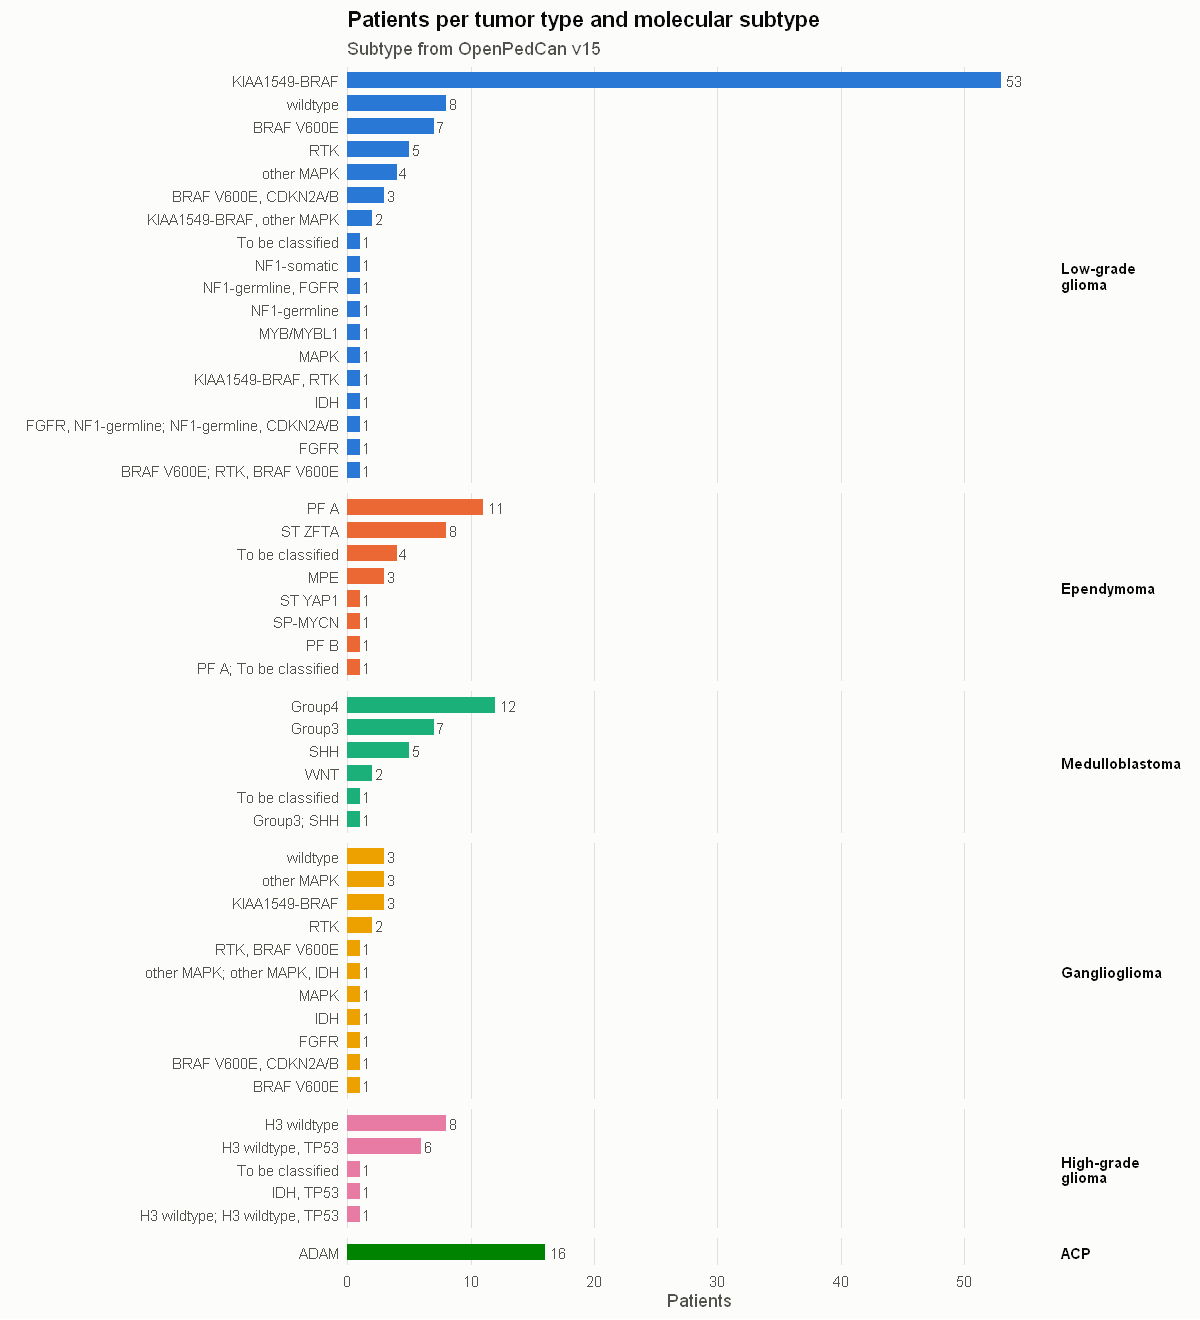

In [7]:
options(repr.plot.width = 10, repr.plot.height = 11)
sub <- pt[tumor_type %in% SIX_TYPES, .N, by = .(tumor_type, molecular_subtype)]
sub[molecular_subtype == "" | is.na(molecular_subtype), molecular_subtype := "Not reported"]
# Drop the tumor-type code in front of each subtype ("LGG, KIAA1549-BRAF" -> "KIAA1549-BRAF")
sub[, molecular_subtype := gsub("(^|; )[A-Z]+, ", "\\1", molecular_subtype)]
sub[, tumor_type := factor(tumor_type, levels = SIX_TYPES)]
sub[, key := reorder(paste(tumor_type, molecular_subtype, sep = "___"), N)]
ggplot(sub, aes(N, key, fill = tumor_type)) +
  geom_col(width = 0.7) +
  geom_text(aes(label = N), hjust = -0.3, size = 3.2, colour = INK[["secondary"]]) +
  facet_grid(tumor_type ~ ., scales = "free_y", space = "free_y",
             labeller = as_labeller(c(setNames(sub(" ", "\n", SIX_TYPES[1:5]), SIX_TYPES[1:5]),
                                      "Adamantinomatous Craniopharyngioma" = "ACP"))) +
  scale_y_discrete(labels = function(x) sub("^.*___", "", x)) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.08))) +
  scale_fill_manual(values = TYPE_COLORS, guide = "none") +
  labs(title = "Patients per tumor type and molecular subtype", subtitle = "Subtype from OpenPedCan v15",
       x = "Patients", y = NULL) +
  theme_bp + theme(strip.text.y = element_text(angle = 0, hjust = 0), panel.spacing.y = unit(6, "pt"))

### Same-sample status by tumor type

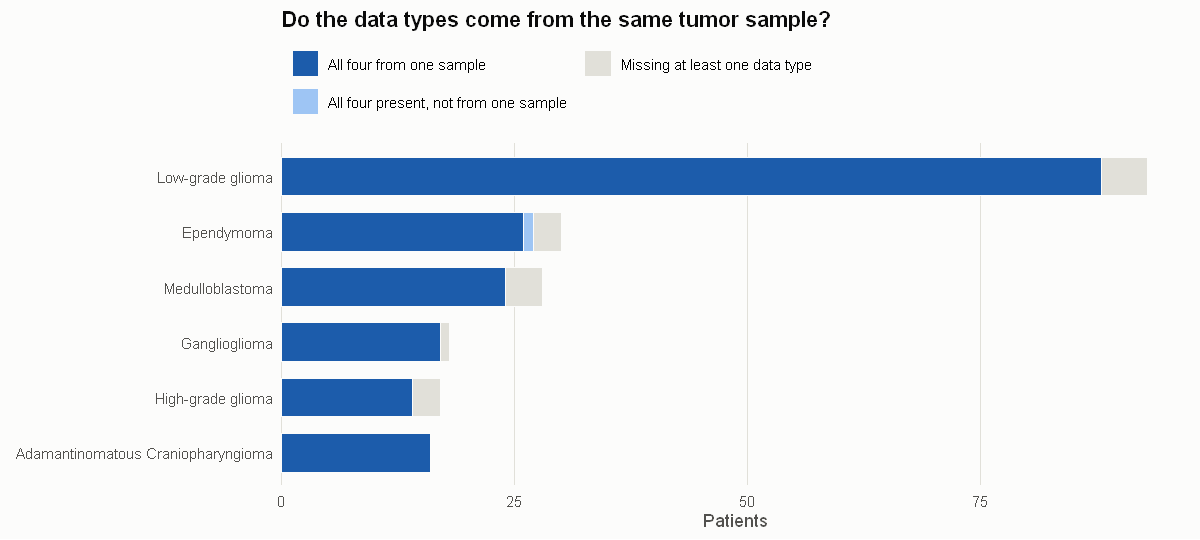

In [8]:
options(repr.plot.width = 10, repr.plot.height = 4.5)
lv <- c("All four from one sample", "WGS, RNA, methylation from one sample; miRNA from another",
        "All four present, not from one sample", "Missing at least one data type")
ss <- pt[tumor_type %in% SIX_TYPES, .N, by = .(tumor_type, same_sample_status)]
ss[, same_sample_status := factor(same_sample_status, levels = rev(lv))]
ss[, tumor_type := factor(tumor_type, levels = rev(SIX_TYPES))]
ggplot(ss, aes(N, tumor_type, fill = same_sample_status)) +
  geom_col(width = 0.7, colour = "#fcfcfb", linewidth = 0.5) +
  scale_fill_manual(values = setNames(c("#1c5cab", "#5598e7", "#9ec5f4", "#e1e0d9"), lv), breaks = lv, name = NULL) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.05))) +
  guides(fill = guide_legend(ncol = 2)) +
  labs(title = "Do the data types come from the same tumor sample?", x = "Patients", y = NULL) +
  theme_bp

In [9]:
dcast(pt[tumor_type %in% SIX_TYPES], tumor_type ~ factor(same_sample_status, levels = lv), fun.aggregate = length, drop = FALSE)

tumor_type,All four from one sample,"WGS, RNA, methylation from one sample; miRNA from another","All four present, not from one sample",Missing at least one data type
<chr>,<int>,<int>,<int>,<int>
Adamantinomatous Craniopharyngioma,16,0,0,0
Ependymoma,26,0,1,3
Ganglioglioma,17,0,0,1
High-grade glioma,14,0,0,3
Low-grade glioma,88,0,0,5
Medulloblastoma,24,0,0,4


### Age at diagnosis and sex

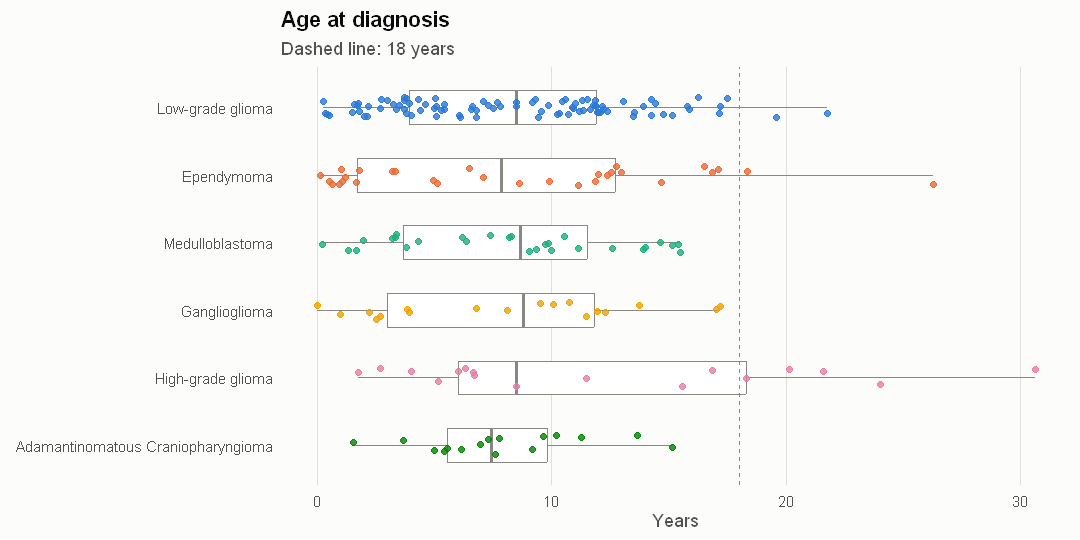

In [10]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
demo <- unique(mirna[, .(patient = Kids_First_Participant_ID, age_years = age_at_diagnosis_days / 365.25,
                         sex = reported_gender)], by = "patient")
demo <- merge(demo, pt[, .(patient, tumor_type)], by = "patient")[tumor_type %in% SIX_TYPES]
demo[, tumor_type := factor(tumor_type, levels = rev(SIX_TYPES))]
ggplot(demo, aes(age_years, tumor_type, colour = tumor_type)) +
  geom_boxplot(outlier.shape = NA, width = 0.5, colour = INK[["muted"]]) +
  geom_jitter(height = 0.15, width = 0, size = 1.6, alpha = 0.8) +
  geom_vline(xintercept = 18, linetype = "dashed", colour = INK[["muted"]], linewidth = 0.4) +
  scale_colour_manual(values = TYPE_COLORS, guide = "none") +
  labs(title = "Age at diagnosis", subtitle = "Dashed line: 18 years", x = "Years", y = NULL) +
  theme_bp

In [11]:
demo[, .(patients = .N, median_age = round(median(age_years, na.rm = TRUE), 1),
         min_age = round(min(age_years, na.rm = TRUE), 1), max_age = round(max(age_years, na.rm = TRUE), 1),
         aged_18_plus = sum(age_years >= 18, na.rm = TRUE),
         female = sum(sex == "Female", na.rm = TRUE), male = sum(sex == "Male", na.rm = TRUE)),
     by = tumor_type][order(tumor_type, decreasing = TRUE)]

tumor_type,patients,median_age,min_age,max_age,aged_18_plus,female,male
<fct>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
Low-grade glioma,93,8.5,0.3,21.8,2,40,53
Ependymoma,30,7.8,0.1,26.3,2,10,20
Medulloblastoma,28,8.7,0.2,15.5,0,13,15
Ganglioglioma,18,8.8,0.0,17.2,0,9,9
High-grade glioma,17,8.5,1.7,30.6,5,11,6
Adamantinomatous Craniopharyngioma,16,7.4,1.5,15.2,0,7,9


## 6. Save outputs

Column order follows Farnoosh's curation rule: the columns we care about on the left, then the rest.

In [12]:
setcolorder(pt, c("patient", "tumor_type", "molecular_subtype", "core_mirna", "same_sample_status", "core", "core_samples",
                  "has_WGS", "has_RNA", "has_methylation", "has_miRNA", "has_snv", "has_cna"))
setcolorder(sample_map, c("patient", "assay", "biospecimen", "sample_id", "snv", "cna", "source", "files"))
fwrite(pt, file.path(OUT, "cohort_patients.csv"))
fwrite(sample_map, file.path(OUT, "sample_map.csv"))

# ICB_Common format (as in ICB_Van_Allen Format_cased_sequenced.R): one row per patient, 0/1 per data type
cased <- pt[, .(patient, snv = as.integer(has_snv), cna = as.integer(has_cna), expr = as.integer(has_RNA),
                methyl = as.integer(has_methylation), mirna = as.integer(has_miRNA))]
write.table(cased, file.path(OUT, "cased_sequenced.csv"), quote = FALSE, sep = ";", row.names = FALSE)

cat("Saved to", OUT, "\n")
cat("cohort_patients.csv:", nrow(pt), "patients\nsample_map.csv:", nrow(sample_map), "rows\ncased_sequenced.csv:",
    nrow(cased), "patients\n\n")
sessionInfo()

Saved to D:\Bidirectional Promoters\bidirectional-promoters/data/procdata/01_cohort 


cohort_patients.csv: 203 patients
sample_map.csv: 1007 rows
cased_sequenced.csv: 203 patients



R version 4.5.3 (2026-03-11 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_Canada.utf8  LC_CTYPE=English_Canada.utf8    LC_MONETARY=English_Canada.utf8
[4] LC_NUMERIC=C                    LC_TIME=English_Canada.utf8    

time zone: America/Toronto
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] scales_1.4.0        UpSetR_1.4.1        ggplot2_4.0.3       data.table_1.18.6.1

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.7.3        cli_3.6.6          rlang_1.3.0        generics_0.1.4     S7_0.2.2          
 [7] jsonlite_2.0.0     labeling_0.4.3     glue_1.8.1         plyr_1.8.9         htmltools_0.5.9    IRdisplay_1.1     
[13] gridExtra_2.3.1    IRkernel_1.3.2     grid_4.5.3         evaluate_1.0.5     tibble_3.3.1       fastmap_1.2.0     
